Your challenge: build it from a blank notebook in 25–30 minutes.
1. Load Iris and use the same 80/20 stratified split with seed 42.
2. Create a pipeline containing StandardScaler and KNeighborsClassifier.
3. Train with n_neighbors=5.
4. Print training and held-out accuracy, then plot a confusion matrix.
5. Use 5-fold grid search on the training set to try:
```
param_grid = {
    "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15],
    "kneighborsclassifier__weights": ["uniform", "distance"],
}
```

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split 
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

In [2]:
X, y = load_iris(return_X_y=True)

In [9]:
X_train, X_t, y_train, y_t = train_test_split(
    X, 
    y, 
    test_size = 0.2,
    stratify=y, 
    random_state=42
)

In [19]:
pipe = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

In [21]:
model = pipe.fit(X_train, y_train)
y_pred = model.predict(X_t)
acc = model.score(X_t, y_t)
print(acc)

0.9333333333333333


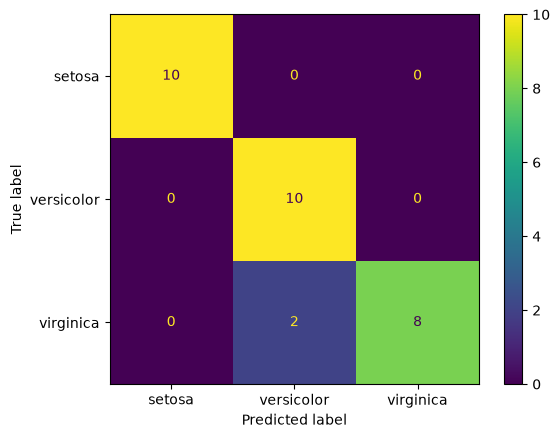

In [31]:
import matplotlib.pyplot as plt 
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay 
cm = confusion_matrix(y_t, y_pred)
graph = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=load_iris().target_names
)
graph.plot()
plt.show()

In [42]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold 

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(
    pipe, 
    param_grid = {
        "kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15],
        "kneighborsclassifier__weights": ["uniform", "distance"],
    },
    scoring="accuracy",
    cv=cv
)


In [52]:
model2 = search.fit(X_train, y_train)
y_pred = search.predict(X_t)
print(search.score(X_t, y_t))

print(search.best_params_)
print(search.best_score_)

0.9333333333333333
{'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'uniform'}
0.9666666666666668


In [53]:
for params, score in zip(
    search.cv_results_["params"],
    search.cv_results_["mean_test_score"],
):
    print(params, f"{score:.2%}")

{'kneighborsclassifier__n_neighbors': 1, 'kneighborsclassifier__weights': 'uniform'} 94.17%
{'kneighborsclassifier__n_neighbors': 1, 'kneighborsclassifier__weights': 'distance'} 94.17%
{'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'uniform'} 96.67%
{'kneighborsclassifier__n_neighbors': 3, 'kneighborsclassifier__weights': 'distance'} 96.67%
{'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'uniform'} 95.83%
{'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'distance'} 95.83%
{'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'uniform'} 93.33%
{'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'distance'} 94.17%
{'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__weights': 'uniform'} 95.00%
{'kneighborsclassifier__n_neighbors': 11, 'kneighborsclassifier__weights': 'distance'} 96.67%
{'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights'

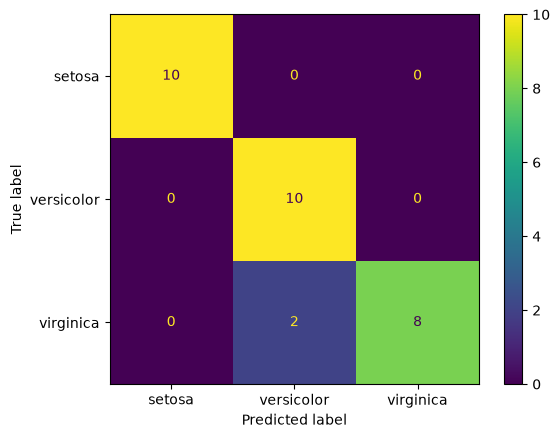

In [50]:
cm = confusion_matrix(y_t, y_pred)
graph = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=load_iris().target_names
)
graph.plot()
plt.show()